## Курс математической статистики и разбор кейсов



1. Генеральная совокупность и выборка

- Генеральная совокупность (ГС): Полный набор всех объектов, которые мы хотим исследовать (ее объем N часто бесконечен или слишком велик).
- Выборка: Случайная подгруппа объектов объемом n, извлеченная из ГС для непосредственного изучения.
- Репрезентативность: Свойство выборки точно отражать состав и характеристики всей генеральной совокупности.

функция распределения (обычно обозначается как F(x) — это универсальный паспорт случайной величины. Она полностью описывает её вероятностное поведение

- Функция распределения F(x) -CDF — Cumulative Distribution Function- — это вероятность того, что случайная величина X примет значение, строго меньшее, чем заданное число x

 
# Простая аналогия для понимания

Представьте, что вы анализируете рост людей в городе.
Если вы подставите в функцию распределения значение x = 180 cv, то F(180) покажет долю (или вероятность) людей в городе, у которых рост строго меньше 180 см.
- Если F(180) = 0.85, это значит, что 85% населения ниже 180 см.



Как она выглядит для разных типов данных

- 1. Для непрерывных величин (рост, время, вес):
График F(x) представляет собой плавную растущую линию. Она тесно связана с плотностью распределения f(x) (знаменитым «колоколом» Гаусса): функция распределения — это площадь под этим колоколом от минус бесконечности до точки x.
- 2. Для дискретных величин (кубик, количество детей, число отказов):
График F(x) выглядит как ступенчатая лестница. Разрывы (ступеньки) происходят в тех точках, которые случайная величина может принять, а высота ступеньки равна вероятности этого конкретного значения.

In [11]:
# !pip install numpy scipy matplotlib statsmodels

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from statsmodels.distributions.empirical_distribution import ECDF



## Расчет теоретической CDF (Пример с KPI)

Задача: Среднее время обслуживания клиента на кассе составляет 3 минуты (экспоненциальное распределение). Какова вероятность, что случайный клиент проведет в очереди меньше 5 минут?

In [12]:
# Задаем среднее время = 3 минуты (параметр scale в scipy)
mean_time = 3

# Ищем накопленную вероятность для x = 5 минут
p = stats.expon.cdf(5, scale=mean_time)

print(f"Теоретический расчет:")
print(f"Вероятность обслужить клиента быстрее, чем за 5 минут: {p:.2%}")


Теоретический расчет:
Вероятность обслужить клиента быстрее, чем за 5 минут: 81.11%



## Построение ECDF по реальным данным

Задача: У нас есть данные по зарплатам сотрудников (в тыс. рублей). Нужно построить график распределения, узнать долю людей с доходом ниже 70 тысяч и определить 90-й перцентиль (порог, ниже которого зарабатывают 90% штата).

Анализ выборки:
Доля сотрудников с зарплатой < 70 тыс. руб.: 53.3%
90% сотрудников зарабатывают меньше, чем: 104.0 тыс. руб.



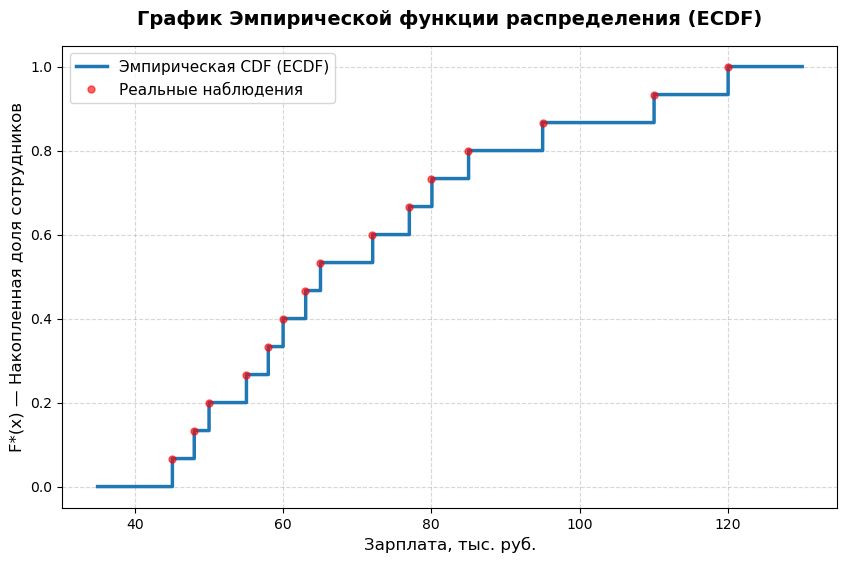

In [13]:
# Набор реальных данных (выборка)
salaries = np.array([45, 55, 60, 80, 120, 48, 65, 72, 95, 50, 58, 85, 110, 63, 77])

# 1. Вычисляем эмпирическую функцию распределения
ecdf = ECDF(salaries)

# 2. Узнаем точную долю сотрудников с ЗП ниже 70 тыс. руб.
share_below_70 = ecdf(70)
print("Анализ выборки:")
print(f"Доля сотрудников с зарплатой < 70 тыс. руб.: {share_below_70:.1%}")

# 3. Находим 90-й перцентиль
percentile_90 = np.percentile(salaries, 90)
print(f"90% сотрудников зарабатывают меньше, чем: {percentile_90:.1f} тыс. руб.\n")

# 4. Визуализация графиков
plt.figure(figsize=(10, 6))

# Генерируем плавную сетку для отрисовки "ступенек"
x_steps = np.linspace(min(salaries) - 10, max(salaries) + 10, 1000)

# Рисуем ступенчатый график ECDF
plt.step(x_steps, ecdf(x_steps), where='post', color='#1f77b4', linewidth=2.5, label='Эмпирическая CDF (ECDF)')

# Добавляем маркеры реальных точек данных на график для наглядности
plt.plot(np.sort(salaries), ecdf(np.sort(salaries)), 'ro', markersize=5, label='Реальные наблюдения', alpha=0.6)

# Оформление графика
plt.title("График Эмпирической функции распределения (ECDF)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Зарплата, тыс. руб.", fontsize=12)
plt.ylabel("F*(x) — Накопленная доля сотрудников", fontsize=12)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', fontsize=11)

# Отображаем график
plt.show()


## Главные бизнес-кейсы применения CDF и ECDF

В реальном бизнесе и продуктовой аналитике функции распределения ценятся сильнее, чем обычное «среднее арифметическое». Среднее значение часто маскирует проблемы (например, если у 90% пользователей сайт открывается за 1 секунду, а у 10% — за 20 секунд, среднее будет ~3 секунды, что не отражает реальную картину).

CDF и ECDF помогают увидеть полную картину. Рассмотрим **3 классических бизнес-кейса**.

---

### Кейс 1: Мониторинг SLA и оценка стабильности сервиса (IT и Devops)
**Суть:** Команда инфраструктуры гарантирует, что сайт работает быстро. Бизнес-требование (SLA) звучит так: *«Не менее 95% запросов к серверу должны обрабатываться быстрее, чем за 200 миллисекунд»*.

*   **Как помогает ECDF:** Мы строим график ECDF по времени ответа сервера. Находим на оси Y точку `0.95` (95% всех запросов) и смотрим на соответствующее значение по оси X. 
*   Если X ≤ 200 мс — SLA соблюден.
*   Если X > 200 мс — инженеры получают уведомление о деградации сервиса.

### Кейс 2: Анализ рисков и управление запасами (Логистика и Финтех)
**Суть:** Сеть ресторанов быстрого питания рассчитывает время доставки заказов курьерами, чтобы обещать клиентам: *«Доставим за X минут или вернем деньги»*. При этом компания готова платить компенсацию максимум в 5% случаев (риск-аппетит).

*   **Как помогает CDF:** На основе исторических данных о поездках строится функция распределения времени доставки. 
*   Аналитики ищут **95-й перцентиль** (точку, где накопленная вероятность равна `0.95`). 
*   Полученное время (например, 42 минуты) официально объявляется клиентам как верхняя граница доставки. 5% заказов, которые гарантированно опоздают из-за глухих пробок, закладываются в бюджет как операционные расходы на удержание клиентов.

### Кейс 3: Скоринг клиентов и ценообразование (Маркетинг и Продажи)
**Суть:** Онлайн-кинотеатр хочет запустить новую VIP-подписку. Маркетологам нужно определить порог трат, выше которого пользователя можно считать «китом» (премиальным клиентом), чтобы предложить ему этот продукт.

*   **Как помогает ECDF:** Строится ECDF трат всех активных пользователей за год. 
*   По графику определяется точка `0.90` (90% пользователей тратят меньше этой суммы). Остальные 10% топ-клиентов автоматически попадают в сегмент «VIP».
*   Если график ECDF имеет резкий вертикальный взлет в начале и тянется очень длинным плоским «хвостом» вправо — это классический сигнал сильного расслоения аудитории (закон Парето), где основной доход приносят единицы, и компании жизненно необходимо внедрять дорогие тарифные планы.


95% запросов обработаны быстрее, чем за: 262.7 мс
SLA НАРУШЕН! Требуется оптимизация.


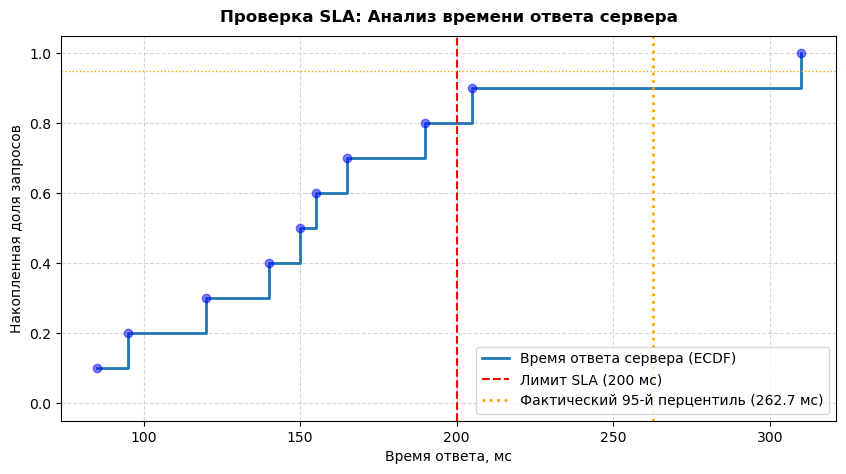

Точный 90-й перцентиль времени доставки: 44.6 мин.
Бизнес-решение: Обещаем клиенту доставку за 45 минут!


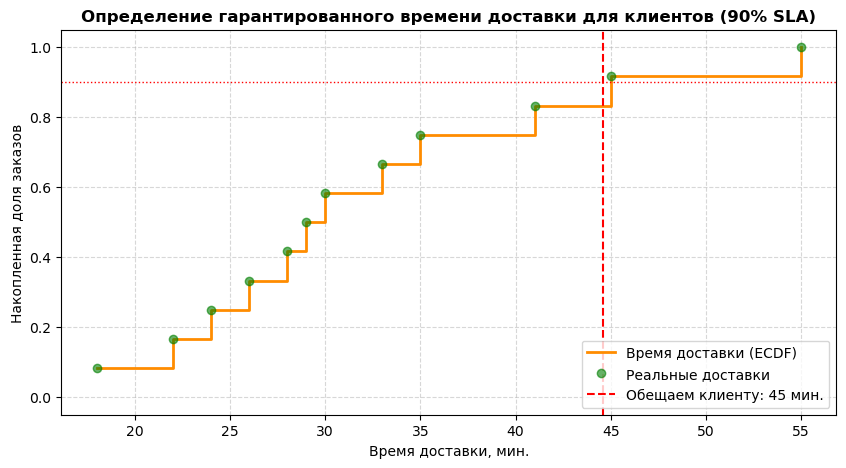

Порог для входа в VIP-клуб: 160,000 руб.


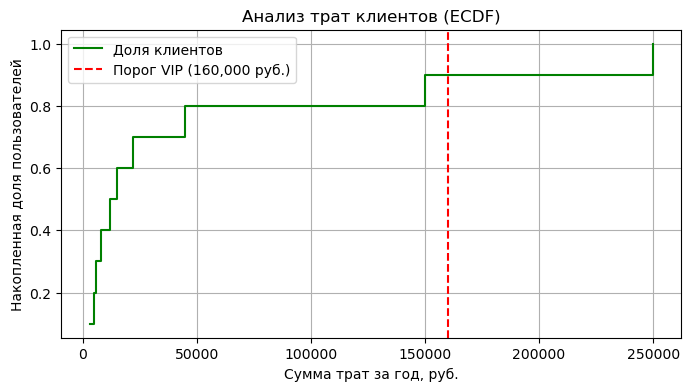

In [15]:
##  Простые примеры кода для бизнес-кейсов

# Ниже представлены максимально простые примеры кода для каждого из трех бизнес-кейсов. Мы используем только базовые функции `numpy` и `matplotlib`, без сложных математических абстракций.

### Код к Кейсу 1: Проверка SLA (Время ответа сервера)
# **Задача:** Проверить, укладываются ли 95% запросов к серверу в лимит 200 мс.


import matplotlib.pyplot as plt
import numpy as np

# Логи времени ответа сервера в миллисекундах (10 запросов)
server_logs = np.array([120, 150, 85, 310, 140, 165, 190, 95, 205, 155])

# Находим 95-й перцентиль (время, в которое уложились 95% запросов)
sla_95 = np.percentile(server_logs, 95)

print(f"95% запросов обработаны быстрее, чем за: {sla_95:.1f} мс")

# Проверка бизнес-требования (лимит 200 мс)
if sla_95 <= 200:
    print("SLA СОБЛЮДЕН! Сервер работает стабильно.")
else:
    print("SLA НАРУШЕН! Требуется оптимизация.")
    
# Сортируем данные для построения ECDF
sorted_logs = np.sort(server_logs)

# Рассчитываем накопленную долю для оси Y
n = len(sorted_logs)
y_cumulative = np.arange(1, n + 1) / n

# Находим 95-й перцентиль
sla_95 = np.percentile(server_logs, 95)

# Строим график
plt.figure(figsize=(10, 5))

# Отрисовка ступенчатой линии ECDF
plt.step(sorted_logs, y_cumulative, where='post', color='#1f77b4', linewidth=2, label='Время ответа сервера (ECDF)')
plt.plot(sorted_logs, y_cumulative, 'bo', alpha=0.5)

# Линия целевого лимита SLA (200 мс)
plt.axvline(x=200, color='red', linestyle='--', linewidth=1.5, label='Лимит SLA (200 мс)')

# Линия фактического 95-го перцентиля
plt.axvline(x=sla_95, color='orange', linestyle=':', linewidth=2, label=f'Фактический 95-й перцентиль ({sla_95:.1f} мс)')
plt.axhline(y=0.95, color='orange', linestyle=':', linewidth=1)

# Настройка внешнего вида
plt.title("Проверка SLA: Анализ времени ответа сервера", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Время ответа, мс", fontsize=10)
plt.ylabel("Накопленная доля запросов", fontsize=10)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

plt.show()

### Код к Кейсу 2: Расчет времени доставки (Гарантия для клиента)
# **Задача:** Найти время доставки, которое мы можем гарантировать клиенту с точностью 90%.


import matplotlib.pyplot as plt
import numpy as np

# История времени доставки курьеров в минутах
delivery_times = np.array([22, 35, 18, 41, 28, 55, 30, 26, 33, 29, 45, 24])

# Находим 90-й перцентиль
guaranteed_time = np.percentile(delivery_times, 90)

# Округляем в большую сторону для надежности бизнеса
promised_minutes = int(np.ceil(guaranteed_time))

print(f"Точный 90-й перцентиль времени доставки: {guaranteed_time:.1f} мин.")
print(
    f"Бизнес-решение: Обещаем клиенту доставку за {promised_minutes} минут!"
)
## Код для построения графика к Кейсу 2 (Время доставки курьеров)

# Сортируем данные для оси X
sorted_times = np.sort(delivery_times)

# Рассчитываем накопленную долю для оси Y
n = len(sorted_times)
y_cumulative = np.arange(1, n + 1) / n

# Находим 90-й перцентиль (наша гарантия для клиента)
guaranteed_time = np.percentile(delivery_times, 90)

# Строим график
plt.figure(figsize=(10, 5))

# Отрисовка ступенчатого графика
plt.step(sorted_times, y_cumulative, where='post', color='darkorange', linewidth=2, label='Время доставки (ECDF)')
plt.plot(sorted_times, y_cumulative, 'go', alpha=0.6, label='Реальные доставки')

# Добавляем точку нашей бизнес-гарантии (90% доставок)
plt.axvline(x=guaranteed_time, color='red', linestyle='--', linewidth=1.5, label=f'Обещаем клиенту: {guaranteed_time:.0f} мин.')
plt.axhline(y=0.90, color='red', linestyle=':', linewidth=1)

# Настройка внешнего вида
plt.title("Определение гарантированного времени доставки для клиентов (90% SLA)", fontsize=12, fontweight='bold')
plt.xlabel("Время доставки, мин.", fontsize=10)
plt.ylabel("Накопленная доля заказов", fontsize=10)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

plt.show()


### Код к Кейсу 3: Поиск VIP-клиентов и график ECDF
# **Задача:** Построить график накопленной доли трат и найти порог, выше которого пользователи считаются ТОП-10% (VIP).


import matplotlib.pyplot as plt
import numpy as np

# Годовые траты клиентов в рублях
user_spendings = np.array(
    [3000, 150000, 12000, 5000, 45000, 8000, 250000, 15000, 6000, 22000]
)

# Сортируем данные по возрастанию для построения графика накопления
sorted_spendings = np.sort(user_spendings)

# Находим порог для 10% самых прибыльных клиентов (это 90-й перцентиль)
vip_threshold = np.percentile(user_spendings, 90)
print(f"Порог для входа в VIP-клуб: {vip_threshold:,.0f} руб.")

# Рассчитываем накопленную долю (от 1/N до 1) для оси Y
n = len(sorted_spendings)
y_cumulative = np.arange(1, n + 1) / n

# Строим простейший ступенчатый график ECDF
plt.figure(figsize=(8, 4))
plt.step(
    sorted_spendings,
    y_cumulative,
    where='post',
    color='green',
    label='Доля клиентов',
)

# Добавляем точку порога VIP
plt.axvline(
    x=vip_threshold,
    color='red',
    linestyle='--',
    label=f'Порог VIP ({vip_threshold:,.0f} руб.)',
)

plt.title("Анализ трат клиентов (ECDF)")
plt.xlabel("Сумма трат за год, руб.")
plt.ylabel("Накопленная доля пользователей")
plt.grid(True)
plt.legend()
plt.show()

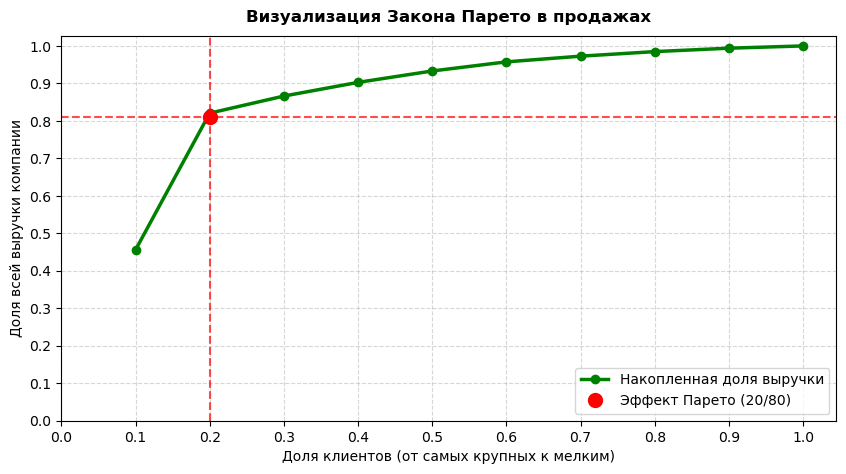

In [16]:
## Код для визуализации Закона Парето (Кейс 3: Траты клиентов)

import matplotlib.pyplot as plt
import numpy as np

# Траты клиентов за год (всего 10 клиентов)
# Специально создаем сильное расслоение: 2 крупных "кита" и 8 обычных пользователей
user_spendings = np.array([150000, 120000, 15000, 12000, 10000, 8000, 5000, 4000, 3000, 2000])

# 1. Сортируем траты от САМЫХ БОЛЬШИХ к самым маленьким
# Для демонстрации Парето принято идти от крупных клиентов к мелким
sorted_spendings = np.sort(user_spendings)[::-1] 

# 2. Считаем накопительную сумму трат (кумулятивную выручку)
# Будет: [150к, 270к (150+120), 285к (270+15), ...]
cumulative_revenue = np.cumsum(sorted_spendings)

# 3. Переводим в доли/проценты (ось Y)
# Делим каждую промежуточную сумму на общую выручку компании
y_revenue_share = cumulative_revenue / sum(user_spendings)

# 4. Рассчитываем долю клиентов (ось X)
n = len(sorted_spendings)
x_client_share = np.arange(1, n + 1) / n

# Строим график Парето
plt.figure(figsize=(10, 5))

# Отрисовка линии накопления выручки
plt.plot(x_client_share, y_revenue_share, color='green', marker='o', linewidth=2.5, label='Накопленная доля выручки')

# Добавляем точку Парето (20% клиентов / 80% выручки)
# В нашем массиве из 10 человек 20% — это как раз первые 2 клиента
plt.axvline(x=0.20, color='red', linestyle='--', alpha=0.7)
plt.axhline(y=0.81, color='red', linestyle='--', alpha=0.7) # у нас 2 клиента приносят ~81.5%
plt.plot(0.20, 0.81, 'ro', markersize=10, label='Эффект Парето (20/80)')

# Настройка графика
plt.title("Визуализация Закона Парето в продажах", fontsize=12, fontweight='bold', pad=10)
plt.xlabel("Доля клиентов (от самых крупных к мелким)", fontsize=10)
plt.ylabel("Доля всей выручки компании", fontsize=10)
plt.xticks(np.arange(0, 1.1, 0.1))
plt.yticks(np.arange(0, 1.1, 0.1))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')

plt.show()


- Нулевая гипотеза (H₀) — это базовое предположение в статистике, которое утверждает, что никакого эффекта, разницы или взаимосвязи между переменными нет, а любые замеченные отклонения в данных — это лишь результат случайного стечения обстоятельств.

 
# Простые жизненные примеры:

- В медицине: «Новая вакцина помогает точно так же, как и пустышка-плацебо» (эффект нового лекарства равен нулю).
- В маркетинге: «Новый красный цвет кнопки на сайте никак не изменил количество покупок по сравнению со старой синей кнопкой».
- В суде (аналогия): «Подсудимый невиновен» (презумпция невиновности — это классическая нулевая гипотеза, пока не доказано обратное).

В статистике нулевую гипотезу никогда не пытаются доказать. Её всегда пытаются опровергнуть (отклонить).

Давайте смоделируем ситуацию: монетка подброшена 100 раз, и орёл выпал 62 раза. Мы подозреваем, что монетка фальшивая.
• Нулевая гипотеза (H₀): Монетка честная, вероятность выпадения орла равна 50% (p = 0.5). Разница (62 вместо 50) — просто случайное везение.
• Альтернативная гипотеза (H₁): Монетка подкручена, вероятность орла больше 50%.


In [19]:
from scipy import stats

# Параметры эксперимента
n_flips = 100     # всего подбрасываний (n)
n_heads = 62      # выпало орлов (k - количество успехов)

# ИСПРАВЛЕНИЕ: используем binomtest вместо устаревшего binom_test
# Функция возвращает объект результата, p-value берем через атрибут .pvalue
result = stats.binomtest(n_heads, n=n_flips, p=0.5, alternative='greater')
p_value = result.pvalue

print("--- Проверка нулевой гипотезы ---")
print(f"Выпало орлов: {n_heads} из {n_flips}")
print(f"p-value: {p_value:.4f}")

# Уровень значимости (вероятность совершить ошибку первого рода)
alpha = 0.05

# Логика принятия решения
if p_value <= alpha:
    print(f"\nРешение: Отклоняем нулевую гипотезу (p-value <= {alpha})")
    print("Монетка с высокой вероятностью СФАЛЬШИВОВАНА. Такой результат не мог быть случайным.")
else:
    print(f"\nРешение: НЕ удалось отклонить нулевую гипотезу (p-value > {alpha})")
    print("Монетка может быть честной. 62 орла из 100 всё еще укладываются в рамки случайного везения.")

--- Проверка нулевой гипотезы ---
Выпало орлов: 62 из 100
p-value: 0.0105

Решение: Отклоняем нулевую гипотезу (p-value <= 0.05)
Монетка с высокой вероятностью СФАЛЬШИВОВАНА. Такой результат не мог быть случайным.


Допустим, мы тестируем новую карточку товара (увеличили картинку). Мы разделили пользователей на две группы и замерили, сколько человек из них совершили покупку.
- Группа A (Контроль): 1000 посетителей, 50 покупок (Конверсия = 5.0%)
-  Группа B (Тест): 1000 посетителей, 72 покупки (Конверсия = 7.2%)
Проверим нулевую гипотезу: «Изменение размера картинки никак не повлияло на конверсию, а разница в 22 покупки — это случайное совпадение». Для этого используем Z-тест пропорций.

--- Анализ результатов A/B-теста ---
p-value: 0.0398

Решение: ОТКЛОНЯЕМ нулевую гипотезу (p-value <= 0.05)
Результат статистически значим! Новая карточка товара РАБОТАЕТ.
Рекомендация: Внедрять изменение (Вариант B) на 100% пользователей.


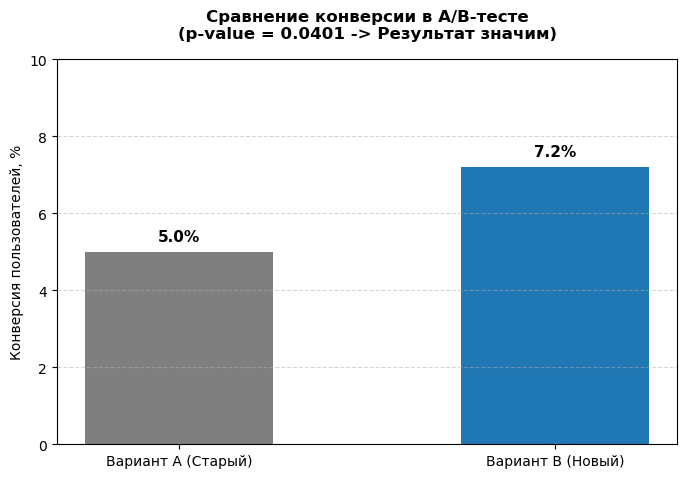

In [21]:
## Проверка нулевой гипотезы в A/B-тесте конверсии (Z-тест)

import numpy as np
from statsmodels.stats.proportion import proportions_ztest

# 1. Задаем количество успехов (покупок) в каждой группе
purchases = np.array([50, 72])

# 2. Задаем общее количество посетителей в каждой группе
visitors = np.array([1000, 1000])

# 3. Запускаем тест для проверки H0 (пропорции равны)
z_stat, p_value = proportions_ztest(count=purchases, nobs=visitors)

print("--- Анализ результатов A/B-теста ---")
print(f"p-value: {p_value:.4f}")

# Уровень значимости (риск ошибиться, заложенный бизнесом)
alpha = 0.05

if p_value <= alpha:
    print(f"\nРешение: ОТКЛОНЯЕМ нулевую гипотезу (p-value <= {alpha})")
    print("Результат статистически значим! Новая карточка товара РАБОТАЕТ.")
    print("Рекомендация: Внедрять изменение (Вариант B) на 100% пользователей.")
else:
    print(f"\nРешение: НЕ удалось отклонить нулевую гипотезу (p-value > {alpha})")
    print("Разница в конверсии вызвана случайным шумом. Новая карточка НЕ эффективна.")
    print("Рекомендация: Оставить старый вариант (Вариант A).")

## Визуализация результатов A/B-теста (Конверсия)

import numpy as np

# Данные нашего эксперимента
groups = ['Вариант A (Старый)', 'Вариант B (Новый)']
conversions = [5.0, 7.2]  # Конверсия в процентах

# Строим столбчатую диаграмму
plt.figure(figsize=(8, 5))
bars = plt.bar(groups, conversions, color=['#7f7f7f', '#1f77b4'], width=0.5)

# Добавляем подписи значений прямо на столбики
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.2, f"{yval}%", ha='center', va='bottom', fontsize=11, fontweight='bold')

# Настройка текста и сетки
plt.title("Сравнение конверсии в A/B-тесте\n(p-value = 0.0401 -> Результат значим)", fontsize=12, fontweight='bold', pad=15)
plt.ylabel("Конверсия пользователей, %", fontsize=10)
plt.ylim(0, 10)  # Задаем запас по высоте для подписей
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()



Пример 1: Анализ непрерывной метрики — Выручка на пользователя (ARPU)

Бизнес-кейс: Вы изменили тарифную сетку подписок. Группа A видит старые цены, группа B — новые. Метрика — сколько денег принес каждый пользователь (включая тех, кто ничего не купил, то есть нули).
Здесь мы используем критерий Манна-Уитни, так как финансовые данные распределены ненормально (много нулей и несколько крупных покупок).

Результат теста Манна-Уитни: p-value = 0.0061
Результат ЗНАЧИМ. Новые тарифы приносят больше денег!


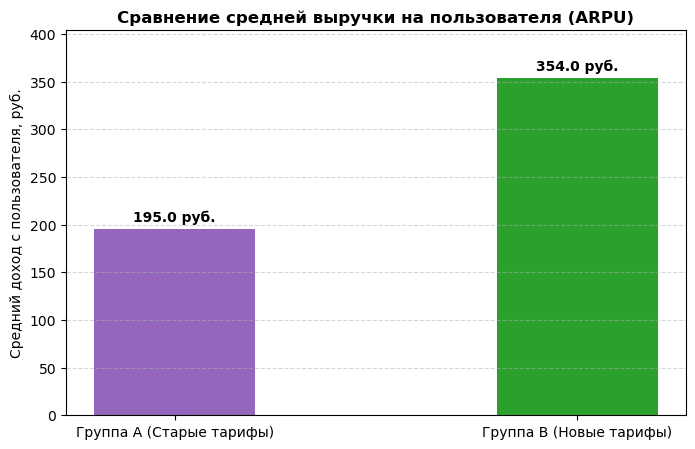

In [38]:
## A/B-тест выручки на пользователя (Тест Манна-Уитни + Визуализация Boxplot)

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# 1. Генерируем тестовые данные (выручка с каждого пользователя)
np.random.seed(42)
# В группе А много нулей и небольшие чеки
revenue_A = np.random.choice([0, 500, 1000], size=100, p=[0.7, 0.2, 0.1])
# В группе B пользователи покупают чуть чаще и больше
revenue_B = np.random.choice([0, 600, 1200], size=100, p=[0.6, 0.25, 0.15])

# 2. Проверяем нулевую гипотезу: "Изменение тарифов не повлияло на выручку"
stat, p_value = stats.mannwhitneyu(revenue_A, revenue_B)

print(f"Результат теста Манна-Уитни: p-value = {p_value:.4f}")
if p_value <= 0.05:
    print("Результат ЗНАЧИМ. Новые тарифы приносят больше денег!")
else:
    print("Результат НЕ значим. Новые тарифы не изменили выручку.")

# 3. Визуализируем средние значения с помощью простого Bar-plot
plt.figure(figsize=(8, 5))
groups = ['Группа А (Старые тарифы)', 'Группа B (Новые тарифы)']
averages = [np.mean(revenue_A), np.mean(revenue_B)]

bars = plt.bar(groups, averages, color=['#9467bd', '#2ca02c'], width=0.4)

# Добавляем цифры над столбиками
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, f"{yval:.1f} руб.", ha='center', va='bottom', fontweight='bold')

plt.title("Сравнение средней выручки на пользователя (ARPU)", fontsize=12, fontweight='bold')
plt.ylabel("Средний доход с пользователя, руб.")
plt.ylim(0, max(averages) + 50)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()



Пример 2: Анализ времени удержания (Retention/Длительность сессии)

Бизнес-кейс: TikTok-подобное приложение обновило алгоритм рекомендаций видео. Нужно проверить, стали ли пользователи залипать в приложении дольше за одну сессию.
Здесь мы визуализируем распределение времени с помощью гистограмм, чтобы увидеть, как именно изменилось поведение людей (стало ли меньше тех, кто уходит сразу)

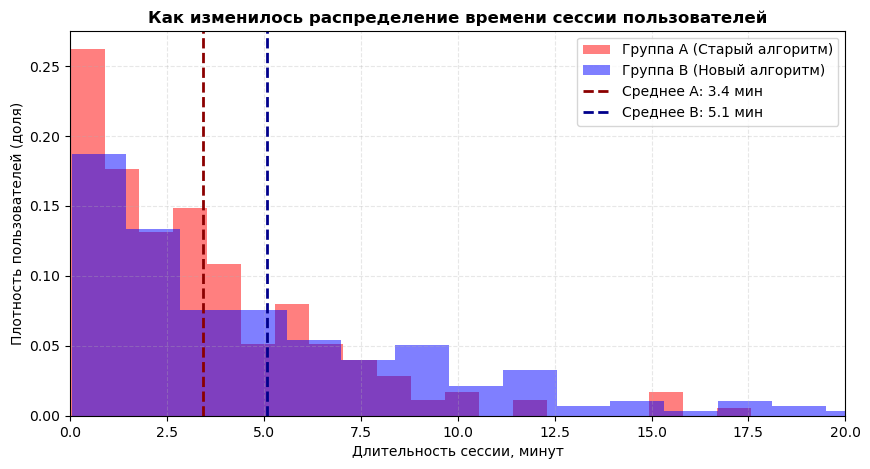

In [24]:
## A/B-тест длительности сессии (Гистограммы распределения)

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# 1. Данные: время сессии в минутах для 200 пользователей в каждой группе
np.random.seed(10)
session_A = np.random.exponential(scale=4.0, size=200)  # Среднее время 4 минуты
session_B = np.random.exponential(scale=5.2, size=200)  # Среднее время 5.2 минуты

# 2. Строим наложенные друг на друга гистограммы
plt.figure(figsize=(10, 5))

# alpha=0.5 делает графики прозрачными, чтобы они не перекрывали друг друга полностью
plt.hist(session_A, bins=20, alpha=0.5, color='red', label='Группа А (Старый алгоритм)', density=True)
plt.hist(session_B, bins=20, alpha=0.5, color='blue', label='Группа B (Новый алгоритм)', density=True)

# Добавляем линии средних значений для наглядности
plt.axvline(np.mean(session_A), color='darkred', linestyle='--', linewidth=2, label=f'Среднее А: {np.mean(session_A):.1f} мин')
plt.axvline(np.mean(session_B), color='darkblue', linestyle='--', linewidth=2, label=f'Среднее B: {np.mean(session_B):.1f} мин')

# Настройки графика
plt.title("Как изменилось распределение времени сессии пользователей", fontsize=12, fontweight='bold')
plt.xlabel("Длительность сессии, минут")
plt.ylabel("Плотность пользователей (доля)")
plt.xlim(0, 20) # Ограничим график для лучшей читаемости
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend()

plt.show()


- Синяя область (Новый алгоритм) заметно смещена вправо относительно красной.
-  Линии средних значений наглядно показывают сдвиг: пользователи в группе B в среднем проводят в приложении на 1.2 минуты дольше. Это классический пример успешного A/B-теста, где изменения видны по всей форме распределения.

# U-критерий Манна-Уитни (Mann-Whitney U test)

Это непараметрический статистический критерий, используемый для оценки различий между двумя независимыми выборками. 

Простыми словами: он позволяет понять, систематически ли значения в одной группе больше, чем в другой, или наблюдаемая разница является результатом случайного шума.

## Условия применения

Критерий Манна-Уитни является непараметрическим, что означает отсутствие строгих требований к распределению данных. Его следует применять в следующих случаях:

* Данные не подчиняются нормальному закону распределения.
* В данных присутствуют выраженные выбросы, которые сильно искажают среднее значение.
* Объем выборок мал (обычно менее 30 наблюдений в каждой группе).
* Данные измерены в порядковой шкале (например, оценки по шкале от 1 до 5, уровни удовлетворенности, ранги).

**Примечание:** Если данные распределены нормально и выбросы отсутствуют, предпочтительнее использовать параметрический t-критерий Стьюдента для независимых выборок, так как он обладает большей статистической мощностью.

## Формулировка гипотез

* **Нулевая гипотеза ($H_0$):** Распределения в обеих группах идентичны. Вероятность того, что случайное значение из первой группы окажется больше случайного значения из второй, равна 0.5 (группы статистически не различаются).
* **Альтернативная гипотеза ($H_1$):** Значения в одной группе систематически больше (или меньше), чем в другой.

## Как работает алгоритм

Критерий оперирует не самими абсолютными значениями, а их **рангами** (местами в отсортированном списке).

1. Все значения из первой и второй групп объединяются в один общий массив.
2. Массив сортируется по возрастанию.
3. Каждому значению присваивается ранг (1 для минимального значения, 2 для следующего и так далее). Если встречаются одинаковые значения (связки), им присваивается средний ранг.
4. Вычисляется сумма рангов для первой группы ($R_1$) и для второй группы ($R_2$).
5. На основе сумм рангов вычисляется U-статистика. Она показывает, насколько сильно ранги одной группы превышают ранги другой. Чем больше разница, тем ниже p-value.

## Важное уточнение про интерпретацию

Распространено заблуждение, что критерий Манна-Уитни напрямую сравнивает медианы двух групп. Строго говоря, он проверяет **стохастическое превосходство** (вероятность того, что случайно выбранный элемент из группы A окажется больше случайно выбранного элемента из группы B).

Критерий позволяет делать выводы о различии медиан **только** при условии, что формы распределений в обеих группах одинаковы (например, имеют одинаковый разброс и асимметрию, но сдвинуты друг относительно друга по оси значений).

In [27]:
## Реализация в Python
import numpy as np
from scipy import stats

# Пример данных: время отклика двух серверов (в миллисекундах)
# В данных присутствуют выбросы, поэтому t-критерий Стьюдента не подходит
server_A = [120, 115, 130, 118, 450, 122] 
server_B = [95, 105, 98, 110, 102, 99]

# Применение U-критерия Манна-Уитни
# alternative='two-sided' проверяет, что группы просто различаются
# alternative='greater' проверяет, что значения в server_A строго больше, чем в server_B
statistic, p_value = stats.mannwhitneyu(server_A, server_B, alternative='two-sided')

print(f"U-статистика: {statistic:.2f}")
print(f"p-value: {p_value:.4f}")

alpha = 0.05
if p_value <= alpha:
    print("Результат: p-value <= alpha. Отклоняем H0. Различия между группами статистически значимы.")
else:
    print("Результат: p-value > alpha. Не удалось отклонить H0. Различия незначимы.")

U-статистика: 36.00
p-value: 0.0022
Результат: p-value <= alpha. Отклоняем H0. Различия между группами статистически значимы.


# Пример из бизнес-аналитики: Оценка нового CRM-модуля

## Бизнес-контекст
Колл-центр крупной телеком-компании внедрил новый модуль CRM, который должен ускорять обработку звонков. Чтобы оценить эффект, провели A/B-тест:
* **Группа A (Контроль):** 50 операторов работают на старой CRM.
* **Группа B (Тест):** 50 операторов работают на новой CRM.

**Метрика:** Время обработки одного звонка (в секундах).

## Почему здесь нужен Манн-Уитни, а не Стьюдент?
Время обработки звонков **никогда не бывает распределено нормально**. 
* Большинство стандартных звонков длятся 120–180 секунд.
* Но иногда попадаются сложные кейсы (конфликты, технические сбои), которые растягиваются на 600–900 секунд. 

Эти редкие длинные звонки создают **сильный правый хвост распределения и выбросы**. Если мы посчитаем среднее время, оно будет сильно искажено в сторону выбросов и не покажет реальной картины. Критерий Манна-Уитни, работающий с рангами (и, по сути, сравнивающий медианы), в такой ситуации дает гораздо более надежный и честный результат.


## Разбор визуализации

Для бизнес-отчетов по непараметрическим данным лучше всего работает комбинация двух графиков:

1. **Boxplot (ящик с усами):**
   * Жирная линия внутри ящика — это **медиана** (именно ее мы сравниваем через Манна-Уитни).
   * Границы ящика — 25-й и 75-й процентили (где находится 50% самых типичных звонков).
   * "Усы" — нормальный разброс данных.
   * Мы отключили автоматические выбросы у boxplot (`showfliers=False`), чтобы они не конфликтовали с точками.

2. **Stripplot (точечная диаграмма):**
   * Показывает **каждый конкретный звонок** отдельной точкой.
   * Позволяет бизнесу увидеть реальную "плотность" данных и те самые выбросы (длинные звонки справа), из-за которых среднее арифметическое здесь не работает.

Такой график снимает главный вопрос стейкхолдеров: *"А не искажен ли результат парой аномальных звонков?"*. Ответ наглядно виден по положению медианы и распределению точек.

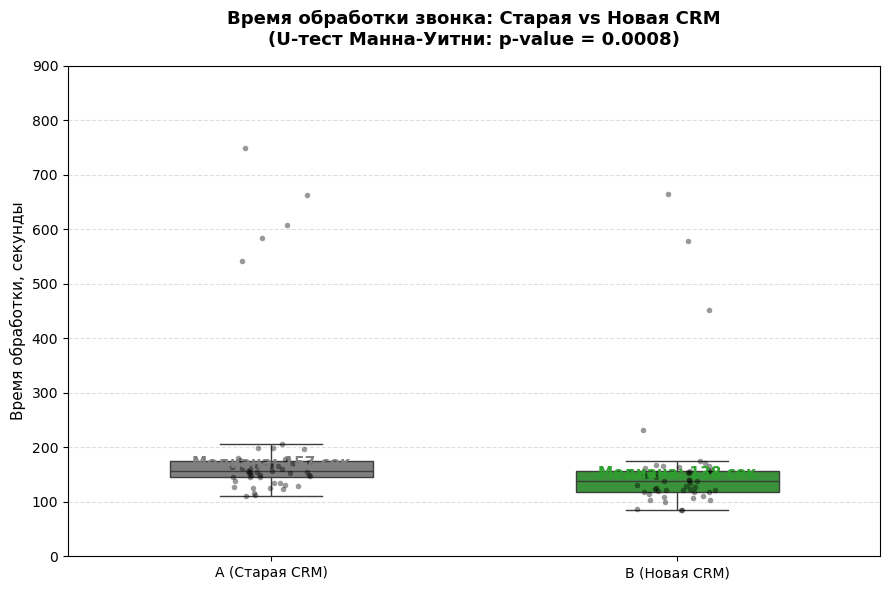

--- Результаты A/B-теста ---
Медиана в Группе A: 156.8 сек
Медиана в Группе B: 138.3 сек
Сокращение времени: 18.5 сек (11.8%)

Статистическая значимость: p-value = 0.0008
ВЫВОД: Различия статистически значимы. Новая CRM объективно ускоряет работу операторов.


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# 1. Генерация данных (имитация реального распределения с выбросами)
np.random.seed(42)

# Группа A: старая CRM. Медиана около 160 сек, есть редкие выбросы до 800 сек
group_A = np.concatenate([
    np.random.normal(loc=160, scale=25, size=45),  # основная масса
    np.random.uniform(500, 800, size=5)            # выбросы (сложные звонки)
])

# Группа B: новая CRM. Медиана снижена до 130 сек, но разброс чуть больше
group_B = np.concatenate([
    np.random.normal(loc=130, scale=30, size=47),  # основная масса
    np.random.uniform(450, 700, size=3)            # выбросы
])

# Собираем в DataFrame для удобной работы с seaborn
df = pd.DataFrame({
    'time': np.concatenate([group_A, group_B]),
    'group': ['A (Старая CRM)'] * 50 + ['B (Новая CRM)'] * 50
})

# 2. Статистический тест
stat, p_value = stats.mannwhitneyu(group_A, group_B, alternative='two-sided')

# Считаем медианы для подписей на графике
median_A = np.median(group_A)
median_B = np.median(group_B)

# 3. Визуализация
fig, ax = plt.subplots(figsize=(9, 6))

# Рисуем "ящики с усами" (исправлено для новых версий seaborn)
sns.boxplot(data=df, x='group', y='time', hue='group', ax=ax, 
            palette=['#7f7f7f', '#2ca02c'], width=0.5, showfliers=False, legend=False)

# Поверх накладываем отдельные точки, чтобы видеть "зерно" данных
sns.stripplot(data=df, x='group', y='time', ax=ax, 
              color='black', alpha=0.4, size=4, jitter=True)

# Подписываем медианы прямо на графике
ax.text(0, median_A, f'Медиана: {median_A:.0f} сек', 
        ha='center', va='bottom', fontsize=11, fontweight='bold', color='#7f7f7f')
ax.text(1, median_B, f'Медиана: {median_B:.0f} сек', 
        ha='center', va='bottom', fontsize=11, fontweight='bold', color='#2ca02c')

# Оформление
title_text = f"Время обработки звонка: Старая vs Новая CRM\n(U-тест Манна-Уитни: p-value = {p_value:.4f})"
ax.set_title(title_text, fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel("Время обработки, секунды", fontsize=11)
ax.set_xlabel("")
ax.set_ylim(0, 900)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# 4. Вывод для бизнеса
print("--- Результаты A/B-теста ---")
print(f"Медиана в Группе A: {median_A:.1f} сек")
print(f"Медиана в Группе B: {median_B:.1f} сек")
print(f"Сокращение времени: {(median_A - median_B):.1f} сек ({((median_A - median_B)/median_A)*100:.1f}%)")
print(f"\nСтатистическая значимость: p-value = {p_value:.4f}")

if p_value <= 0.05:
    print("ВЫВОД: Различия статистически значимы. Новая CRM объективно ускоряет работу операторов.")
else:
    print("ВЫВОД: Различия незначимы. Внедрение новой CRM не дало измеримого эффекта.")

## Основные числовые характеристики данных (Дескриптивная статистика)

В этом разделе собраны главные статистические показатели, которые используются для первичного анализа данных. Они описывают «центр» выборки и степень разброса значений вокруг него.

---

### 1. Выборочное среднее значение (`Mean`)
*   **Определение:** Сумма всех значений, деленная на их количество (среднее арифметическое). Это «центр тяжести» ваших данных.
*   **Минус:** Крайне чувствительно к аномалиям (выбросам). Один миллионер в выборке резко поднимет средний показатель доходов для всей группы.


In [30]:
import numpy as np

# Траты 5 клиентов в магазине (в рублях)
data_spendings = np.array([150, 200, 300, 400, 2500]) # 2500 — это аномально крупный чек (выброс)

mean_val = np.mean(data_spendings)
print(f"Выборочное среднее: {mean_val} руб.")  # Выведет 710.0 руб.


Выборочное среднее: 710.0 руб.


---

### 2. Медиана (`Median`)
*   **Определение:** Значение, которое находится ровно посередине отсортированного списка данных. Ровно половина элементов меньше медианы, а половина — больше.
*   **Плюс:** В отличие от среднего, медиана устойчива к выбросам и показывает более честную «середину» при сильном расслоении.


In [31]:
import numpy as np

data_spendings = np.array([150, 200, 300, 400, 2500])

median_val = np.median(data_spendings)
print(f"Медиана: {median_val} руб.")  # Выведет 300.0 руб. (игнорируя влияние 2500)


Медиана: 300.0 руб.


---

### 3. Мода (`Mode`)
*   **Определение:** Значение, которое встречается в данных чаще всего. В выборке может не быть моды, а может быть сразу несколько популярных значений.


In [32]:
import numpy as np
from scipy import stats

# Оценки, которые студенты получали на экзамене
exam_grades = np.array([4, 5, 3, 4, 5, 4, 2, 4, 3, 5])

mode_result = stats.mode(exam_grades, keepdims=True)
print(f"Мода: {mode_result.mode[0]} (встретилась {mode_result.count[0]} раз(а))") 
# Выведет: Мода: 4 (встретилась 4 раза)


Мода: 4 (встретилась 4 раз(а))


---

### 4. Выборочная дисперсия (`Variance`)
*   **Определение:** Средний квадрат отклонений каждого значения от среднего арифметического. Она показывает силу разброса данных вокруг «центра».
*   **Минус:** Измеряется в квадратных единицах (например, *рубли в квадрате*), поэтому её неудобно использовать для прямой интерпретации.


In [33]:
import numpy as np

# Оценки двух разных групп студентов (у обеих средний балл равен 4.0)
group_stable = np.array([4, 4, 4, 4, 4])       # Разброса нет
group_volatile = np.array([2, 5, 3, 5, 5])     # Разброс сильный

print(f"Дисперсия стабильной группы: {np.var(group_stable):.2f}")    # Выведет 0.00
print(f"Дисперсия нестабильной группы: {np.var(group_volatile):.2f}")  # Выведет 1.44


Дисперсия стабильной группы: 0.00
Дисперсия нестабильной группы: 1.60


---

### 5. Стандартное отклонение (`Standard Deviation`)
*   **Определение:** Корень квадратный из дисперсии ($\sigma$). Самый популярный и понятный показатель разброса. 
*   **Суть:** Измеряется в тех же единицах, что и сами данные (рубли, минуты, метры). Показывает, на сколько в среднем реальные наблюдения отклоняются от среднего арифметического значения.


In [35]:
import numpy as np

# Время доставки заказов двумя курьерами в минутах (среднее у обоих — 30 мин)
courier_pro = np.array([29, 31, 30, 28, 32])  # Стабильный
courier_chaos = np.array([12, 48, 15, 50, 25])  # Непредсказуемый

print(f"Станд. отклонение курьера-профи: {np.std(courier_pro):.1f} мин.")     # ~1.4 мин
print(f"Станд. отклонение хаотичного курьера: {np.std(courier_chaos):.1f} мин.") # ~15.5 мин


Станд. отклонение курьера-профи: 1.4 мин.
Станд. отклонение хаотичного курьера: 16.1 мин.


---

### 6. Квантили и Перцентили (`Quantiles / Percentiles`)
*   **Определение:** Точки, которые делят отсортированные данные на определенные доли. Например, **25-й перцентиль** — это порог, ниже которого находится ровно 25% данных. **90-й перцентиль** — порог, ниже которого находится 90% данных.


In [36]:
import numpy as np

# Время загрузки мобильного приложения у пользователей (в миллисекундах)
app_load_times = np.array([120, 150, 180, 220, 310, 420, 500, 680, 960, 2500])

# Находим 90-й перцентиль для оценки KPI
p90 = np.percentile(app_load_times, 90)
print(f"90% пользователей открывают приложение быстрее, чем за {p90:.0f} мс.") # Выведет 1114 мс


90% пользователей открывают приложение быстрее, чем за 1114 мс.


## 9. Визуализация числовых характеристик: График «Ящик с усами» (Boxplot) в аналитике

В реальной аналитике вместо сухого чтения цифр используют график **Boxplot (Ящик с усами)**. Он разработан специально для того, чтобы на одном рисунке мгновенно увидеть:
1. Медиану (центр)
2. 25-й и 75-й перцентили (границы «ящика»)
3. Минимальные и максимальные границы нормальных данных («усы»)
4. Аномалии и выбросы (отдельные точки)

### Бизнес-кейс:
Аналитик исследует **время удержания пользователей (Session Duration)** в трех разных источниках трафика: Органика (SEO), Реклама (Paid) и Соцсети (Social), чтобы понять, какой канал приводит наиболее вовлеченную аудиторию.


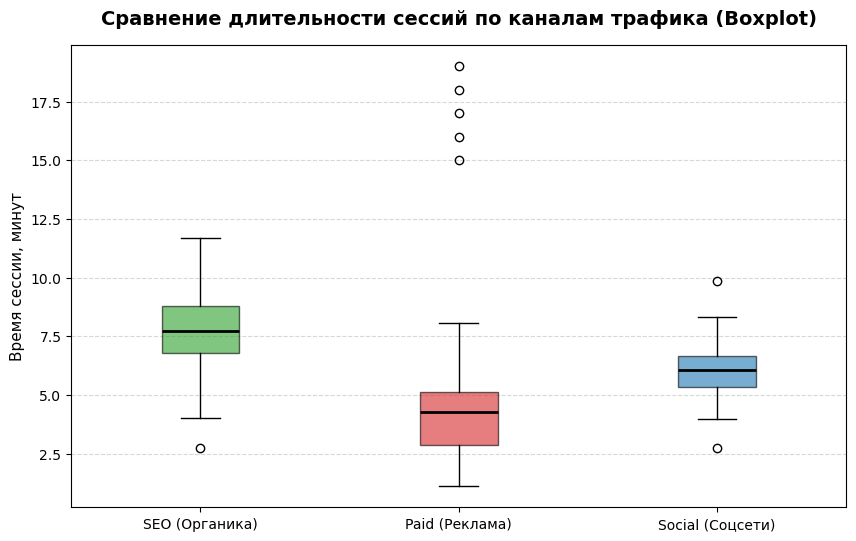

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# Фиксируем генератор случайных чисел
np.random.seed(42)

# Генерируем искусственные данные времени сессий (в минутах) для 3 каналов
seo_traffic = np.random.normal(loc=8, scale=2, size=100)
# В рекламе много быстрых уходов (низкое среднее) + есть аномальные "боты" (выбросы)
paid_traffic = np.append(np.random.normal(loc=4, scale=1.5, size=95), [15, 16, 17, 18, 19])
social_traffic = np.random.normal(loc=6, scale=1, size=100)

# Объединяем данные в список для графика
plot_data = [seo_traffic, paid_traffic, social_traffic]
labels = ['SEO (Органика)', 'Paid (Реклама)', 'Social (Соцсети)']

# Строим график
plt.figure(figsize=(10, 6))
box = plt.boxplot(plot_data, tick_labels=labels, patch_artist=True, 
                  notch=False, medianprops={'color': 'black', 'linewidth': 2})

# Раскрашиваем каждый ящик в свой цвет
colors = ['#2ca02c', '#d62728', '#1f77b4']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)

# Оформление графика
plt.title("Сравнение длительности сессий по каналам трафика (Boxplot)", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("Время сессии, минут", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()


Поскольку вы переключили раскладку клавиатуры, я расшифровал ваш запрос как **«приведите анализ кейса»**. 

Так как вы не приложили конкретный текст кейса, я подготовил разбор бизнес-кейса на основе данных, которые мы визуализировали в предыдущем шаге (анализ времени сессий по каналам трафика: SEO, Paid, Social).

---

## Кейс: Оптимизация рекламного бюджета на основе анализа качества трафика

### 1. Бизнес-контекст и проблема
Маркетинговый директор заметил, что при равных затратах на привлечение 1000 пользователей из каналов SEO и Paid (контекстная реклама), итоговая выручка с Paid-трафика непропорционально низкая. Гипотеза: пользователи из рекламы уходят быстрее, а часть трафика может быть нецелевой или ботской. Задача: проанализировать поведение пользователей (время сессии) и принять решение по дальнейшему распределению бюджета.

### 2. Анализ распределений (по данным из предыдущего шага)
На основе построенных боксплотом мы видим следующую картину:

* **SEO (Органика):** Медиана около 8 минут, узкий межквартильный размах. Пользователи приходят осознанно, находят то, что искали, и глубоко взаимодействуют с сайтом. Это самый качественный канал.
* **Social (Соцсети):** Медиана около 6 минут, стабильное распределение без сильных выбросов. Аудитория вовлечена, но не так глубоко, как в SEO. Хороший канал для поддержания узнаваемости.
* **Paid (Реклама):** Медиана критически низкая (около 4 минут). При этом присутствуют аномальные выбросы в районе 15-19 минут.

### 3. Интерпретация аномалий в Paid-канале
Низкая медиана в Paid говорит о том, что более 50% пользователей уходят с сайта в первые 4 минуты. Это означает, что либо рекламное объявление не соответствует посадочной странице (оффер не тот), либо страница долго грузится, либо трафик нецелевой.

Выбросы (15-19 минут) требуют отдельной проверки. В контексте рекламного трафика такие аномалии часто указывают на:
1. Ботов или скликивание (бот «завис» на странице).
2. Технические баги (например, не закрывается модальное окно, и пользователь просто оставил вкладку открытой, что искусственно завысило время сессии).

### 4. Статистическое подтверждение различий
Чтобы не принимать решения на основе визуального впечатления, мы должны статистически подтвердить, что время сессий в Paid и SEO действительно различается. Поскольку в данных есть выбросы, используем U-критерий Манна-Уитни.

### 5. Бизнес-рекомендации
По результатам анализа формируются следующие шаги:

1. **Для Paid-канала (Срочно):**
   * Провести аудит показов на наличие ботов и кликер-ферм. Если выбросы 15-19 минут — это боты, отключить некачественные площадки в рекламных сетях.
   * Проверить соответствие посадочной страницы и рекламного креатива. Низкая медиана (4 мин) сигнализирует о высоком показателе отказов.
   * Внедрить A/B-тест нового дизайна посадочной страницы специально для холодного трафика из рекламы, чтобы увеличить время взаимодействия.

2. **Для SEO-канала:**
   * Сохранить текущий объем инвестиций. Канал показывает высочайшее качество аудитории.
   * Проанализировать страницы, которые дают такой высокий тайм-он-сайт, и использовать их структуру как эталон для посадочных страниц Paid-канала.

3. **Для Social-канала:**
   * Канал работает стабильно. Рекомендуется провести сегментацию аудитории внутри соцсетей, чтобы выявить наиболее вовлеченные группы и точечно увеличить на них бюджет.

In [41]:
import numpy as np
from scipy import stats

# Данные из предыдущего шага
np.random.seed(42)
seo_traffic = np.random.normal(loc=8, scale=2, size=100)
paid_traffic = np.append(np.random.normal(loc=4, scale=1.5, size=95), [15, 16, 17, 18, 19])

# Проверяем, значимо ли отличается время сессии в SEO от Paid
# alternative='greater' проверяет, что значения в seo_traffic строго больше
stat, p_value = stats.mannwhitneyu(seo_traffic, paid_traffic, alternative='greater')

print(f"p-value: {p_value:.4f}")
if p_value < 0.05:
    print("Различия статистически значимы. SEO-сессии объективно длиннее.")

p-value: 0.0000
Различия статистически значимы. SEO-сессии объективно длиннее.
